# Predicting customer booking completion

This is the canonical Task 2 working notebook. It compares a historical random forest, logistic regression and CatBoost using the same five grouped development folds. **The selected model and its inference helper are CatBoost**; the original forest files in `model/forest_benchmark/` remain historical benchmarks. New selected-model artifacts live in `model/selected/`.

Forage asks for data exploration/preparation, a predictive model, cross-validation with suitable metrics, variable-contribution visualisation, and **one manager-facing PowerPoint slide**. See the [task](https://www.theforage.com/virtual-experience/NjynCWzGSaWXQCxSX/british-airways/data-science-yqoz/predicting-customer-buying-behaviour?step=3). The live resource list mentions a template in prose but does not expose a template download.

Run all cells with **Python (BA Forage)** (`task2/.venv/bin/python`). This notebook deliberately refits the development models rather than silently trusting cached scores. It runs from the project root or `task2/`. The folder cleanup retains one canonical working notebook.

In [1]:
from pathlib import Path
import hashlib, importlib.metadata, json, sys, warnings
import cloudpickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, accuracy_score, confusion_matrix, precision_recall_curve, brier_score_loss)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.inspection import permutation_importance
from catboost import CatBoostClassifier

BASE = Path.cwd() if Path('data/customer_booking.csv').exists() else Path.cwd() / 'task2'
sys.path.insert(0, str(BASE.resolve()))
from booking_model import RAW_COLUMNS, CATEGORICAL, NUMERIC, add_airport_endpoints, predict_completed, load_selected
MODEL_DIR = BASE / 'model'
FOREST_DIR = MODEL_DIR / 'forest_benchmark'
SELECTED_DIR = MODEL_DIR / 'selected'
RESULTS_DIR = BASE / 'results'
SELECTED_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
versions = {p: importlib.metadata.version(p) for p in
            ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'cloudpickle', 'catboost']}
for line in (BASE / 'requirements.txt').read_text().splitlines():
    if line and not line.startswith('#'):
        package, expected = line.split('==')
        assert importlib.metadata.version(package) == expected, f'Use project environment for {package}'
forest_manifest = json.loads((FOREST_DIR / 'manifest.json').read_text())
for filename, expected in forest_manifest['assets_sha256'].items():
    assert sha256(FOREST_DIR / filename) == expected, f'Changed historical asset: {filename}'
assert sha256(BASE / 'data/customer_booking.csv') == forest_manifest['data_sha256']
data = pd.read_csv(BASE / 'data/customer_booking.csv', encoding='ISO-8859-1')
print('Python:', sys.version.split()[0])
print('Versions:', versions)

Matplotlib is building the font cache; this may take a moment.


Python: 3.13.16
Versions: {'numpy': '2.5.4', 'pandas': '3.1.0', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'cloudpickle': '3.1.2', 'catboost': '1.2.10'}


## 1. Understand the records before modelling

The starter notebook defines `booking_complete` as the completion flag, `booking_origin` as the country where the booking was made, `purchase_lead` as days between booking and travel, and the three `wants_...` fields as booking preferences. Flight day/hour describe departure, not a booking timestamp. These fields do not identify a customer.

The starter describes `route` as an origin/destination route. In this file **all route strings have alphabetically ordered endpoints**, so their positions do not establish travel direction. We derive neutral `airport_1` and `airport_2` features within each pipeline. Weekday remains categorical: mapping Monday to 1 does not make its relationship with completion linear.

We retain repeated rows because no source evidence establishes that they are accidental copies. Conflicting outcomes for identical inputs can reflect omitted information or label errors; deleting them would manufacture certainty. Matching inputs stay together in every split. Extreme lead/stay values and rare categories are inspected, not automatically removed.

**Availability assumption:** all inputs, including preferences, must exist when a booking is scored and before completion. The documentation does not establish collection timing. This is a condition for operational use, not proof that the preference fields leak the outcome. This model describes booking-stage behaviour and cannot automatically score a prospect with none of these inputs.

rows                            50000
completions                      7478
extra_exact_duplicates            719
unique_predictor_patterns       49273
conflicting_patterns                8
rows_in_conflicting_patterns       16
dtype: int64

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


,Missing,Distinct
num_passengers,0,9
sales_channel,0,2
trip_type,0,3
purchase_lead,0,470
length_of_stay,0,335
flight_hour,0,24
flight_day,0,7
route,0,799
booking_origin,0,104
wants_extra_baggage,0,2


,count,mean,std,min,25%,50%,75%,max
num_passengers,50000.0,1.591240,1.020165,1.00,1.00,1.00,2.00,9.0
purchase_lead,50000.0,84.940480,90.451378,0.00,21.00,51.00,115.00,867.0
length_of_stay,50000.0,23.044560,33.887670,0.00,5.00,17.00,28.00,778.0
flight_hour,50000.0,9.066340,5.412660,0.00,5.00,9.00,13.00,23.0
wants_extra_baggage,50000.0,0.668780,0.470657,0.00,0.00,1.00,1.00,1.0
wants_preferred_seat,50000.0,0.296960,0.456923,0.00,0.00,0.00,1.00,1.0
wants_in_flight_meals,50000.0,0.427140,0.494668,0.00,0.00,0.00,1.00,1.0
flight_duration,50000.0,7.277561,1.496863,4.67,5.62,7.57,8.83,9.5


Alphabetically ordered endpoints: 1.0
Completion prevalence: 14.96%; always predict no completion: 85.04% accuracy, 0% recall.


Rare categories (fewer than 10 rows): {'route': 296, 'booking_origin': 63}


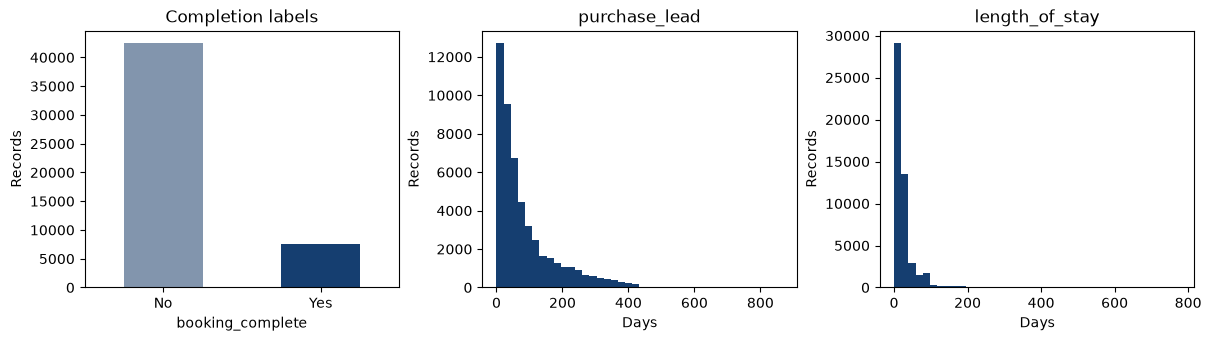

In [2]:
X = data.drop(columns='booking_complete')
y = data['booking_complete']
assert list(X) == RAW_COLUMNS == forest_manifest['required_raw_columns']
assert set(y.unique()) == {0, 1}
assert not data.isna().any().any()
add_airport_endpoints(X)  # validate the raw schema and value domains
# A group is an identical set of original input values, not an identified customer.
groups = X.groupby(list(X.columns), dropna=False).ngroup()
label_counts = y.groupby(groups).nunique()
conflicting_groups = label_counts[label_counts > 1].index
audit_counts = {'rows': len(data), 'completions': int(y.sum()),
    'extra_exact_duplicates': int(data.duplicated().sum()),
    'unique_predictor_patterns': int(groups.nunique()),
    'conflicting_patterns': len(conflicting_groups),
    'rows_in_conflicting_patterns': int(groups.isin(conflicting_groups).sum())}
display(pd.Series(audit_counts))
display(data.head())
display(pd.DataFrame({'Missing': data.isna().sum(), 'Distinct': data.nunique()}))
display(X[NUMERIC].describe().T)
print('Alphabetically ordered endpoints:', (X.route.str[:3] < X.route.str[3:]).mean())
print(f'Completion prevalence: {y.mean():.2%}; always predict no completion: {1-y.mean():.2%} accuracy, 0% recall.')
print('Rare categories (fewer than 10 rows):', {c: int((X[c].value_counts() < 10).sum()) for c in ['route', 'booking_origin']})
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), layout='constrained')
y.value_counts().sort_index().plot.bar(ax=axes[0], color=['#8295AD','#153E70'], rot=0)
axes[0].set(title='Completion labels', xticklabels=['No', 'Yes'], ylabel='Records')
for ax, column in zip(axes[1:], ['purchase_lead','length_of_stay']):
    ax.hist(X[column], bins=40, color='#153E70'); ax.set(title=column, ylabel='Records', xlabel='Days')
plt.show(); plt.close(fig)

## 2. Keep matching booking details together

About 80% of the records form the development set. Five-fold cross-validation fits on four development folds and predicts the fifth, repeating until every development row has an **out-of-fold (OOF)** prediction. Encoders, scaling and CatBoost's category learning only see each fold's training rows.

Grouping prevents exact repeated input patterns appearing on both sides of a split. With no customer ID or dated booking sequence, it cannot establish performance on new customers or a future time period. Reusing these folds for multiple model choices also introduces selection optimism; their scores are development estimates.

In [3]:
development_rows, reserved_rows = next(GroupShuffleSplit(n_splits=1, test_size=0.20,
    random_state=42).split(X, y, groups))
X_dev, y_dev = X.iloc[development_rows].copy(), y.iloc[development_rows].copy()
development_groups = groups.iloc[development_rows]
assert set(development_groups).isdisjoint(groups.iloc[reserved_rows])
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X_dev, y_dev, development_groups))
fold_id, coverage = np.zeros(len(X_dev), dtype=int), np.zeros(len(X_dev), dtype=int)
for number, (training, validation) in enumerate(folds, 1):
    assert set(training).isdisjoint(validation)
    assert set(development_groups.iloc[training]).isdisjoint(development_groups.iloc[validation])
    fold_id[validation] = number
    coverage[validation] += 1
assert (coverage == 1).all()
print(f'Development: {len(X_dev):,}; holdout: {len(reserved_rows):,}')
display(pd.DataFrame({'fold':fold_id, 'target':y_dev.to_numpy()}).groupby('fold').target.agg(['size','mean']))
# Verify row, target, group AND fold alignment before comparing any historical cache.
forest_cache = np.load(FOREST_DIR / 'development_predictions.npz')
for key, expected in [('original_row',X_dev.index),('target',y_dev),('group',development_groups),('fold',fold_id)]:
    np.testing.assert_array_equal(forest_cache[key], expected)
assert np.isfinite(forest_cache['probability']).all()
forest_saved_folds = pd.read_csv(FOREST_DIR / 'development_folds.csv')
for number, (_, validation) in enumerate(folds,1):
    np.testing.assert_allclose(average_precision_score(y_dev.iloc[validation],forest_cache['probability'][validation]),
        forest_saved_folds.loc[forest_saved_folds.fold == number,'validation_AP'].item(),atol=1e-12)

Development: 39,974; holdout: 10,026


,size,mean
fold,,
1,7995,0.150094
2,7995,0.150219
3,7995,0.150094
4,7994,0.150113
5,7995,0.150219


## 3. Reproduce the benchmarks and investigate two specific changes

**Average precision (AP)** summarises precision across recall levels. A constant score has AP equal to completion prevalence, approximately 0.15. AP is our primary ranking metric; ROC-AUC is supplementary. Accuracy alone rewards the 85% majority class even when we find no completions.

Logistic regression tests a simpler relationship after one-hot encoding and numeric scaling. The forest learns nonlinear rules. CatBoost also learns nonlinear rules and handles categorical variables directly, including rare routes. Class weighting is not automatically beneficial for AP or calibrated probabilities, so we retain the observed class distribution.

The earlier four CatBoost configurations tested extra depth and more trees. We reproduce those results and add **only two** motivated checks: L2 regularization 30 instead of 10 (discourages extreme leaf estimates), and learning rate 0.025 with 1,000 trees instead of 0.05 with 500 (smaller learning steps with similar total budget). We do not expand the search after seeing results.

Before running: retain the existing CatBoost unless a challenger improves mean fold AP by at least 0.002 and improves at least four of the five paired folds. This is a practical guard against chasing tiny changes, not a statistical significance test.

`cat_features` is supplied to **fit**, not the CatBoost constructor, to avoid the installed version's sklearn cloning incompatibility. Every configuration uses exactly the same fold indices.

In [4]:
def build_forest():
    return Pipeline([
        ('airport_features', FunctionTransformer(add_airport_endpoints, validate=False)),
        ('preparation', ColumnTransformer([
            ('categories', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
            ('numbers','passthrough',NUMERIC)])),
        ('classifier',RandomForestClassifier(**forest_manifest['parameters'], n_jobs=4))])

def build_logistic():
    return Pipeline([
        ('airport_features',FunctionTransformer(add_airport_endpoints,validate=False)),
        ('preparation',ColumnTransformer([
            ('categories',OneHotEncoder(handle_unknown='ignore'),CATEGORICAL),
            ('numbers',StandardScaler(),NUMERIC)])),
        ('classifier',LogisticRegression(C=1.0,max_iter=2000))])

CATBOOST_BASE = dict(iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=10,
    loss_function='Logloss', random_seed=42, thread_count=4, verbose=False, allow_writing_files=False)
def build_catboost(settings):
    return Pipeline([('airport_features',FunctionTransformer(add_airport_endpoints,validate=False)),
        ('classifier',CatBoostClassifier(**settings))])

def evaluate_development(estimator, catboost=False):
    return cross_validate(estimator, X_dev, y_dev, cv=folds,
        scoring={'AP':'average_precision','AUC':'roc_auc'},
        params={'classifier__cat_features':CATEGORICAL} if catboost else None,
        return_train_score=True, return_estimator=True, n_jobs=1, error_score='raise')

def oof_predictions(result):
    probability = np.full(len(X_dev), np.nan)
    for (_, validation), fitted in zip(folds,result['estimator']):
        probability[validation] = fitted.predict_proba(X_dev.iloc[validation])[:,1]
    assert np.isfinite(probability).all()
    return probability

forest_results = evaluate_development(build_forest())
forest_oof = oof_predictions(forest_results)
np.testing.assert_allclose(forest_oof, forest_cache['probability'], rtol=0, atol=1e-12)
np.testing.assert_allclose(forest_results['train_AP'], forest_saved_folds.train_AP, rtol=0, atol=1e-12)
print('Fresh forest fits reproduce historical OOF probabilities and training AP.')
logistic_results = evaluate_development(build_logistic())
print('Logistic regression finished.')

Fresh forest fits reproduce historical OOF probabilities and training AP.


Logistic regression finished.


In [5]:
catboost_settings = {
    'original_d6_i500': CATBOOST_BASE,
    'historical_d8_i500': dict(CATBOOST_BASE, depth=8),
    'historical_d6_i1000': dict(CATBOOST_BASE, iterations=1000),
    'historical_d8_i1000': dict(CATBOOST_BASE, depth=8, iterations=1000),
    'stronger_l2': dict(CATBOOST_BASE,l2_leaf_reg=30),
    'slower_learning': dict(CATBOOST_BASE,learning_rate=0.025,iterations=1000)}
catboost_results = {}
for name, settings in catboost_settings.items():
    catboost_results[name] = evaluate_development(build_catboost(settings), catboost=True)
    result = catboost_results[name]
    print(f'{name}: train AP {result["train_AP"].mean():.4f}; validation AP {result["test_AP"].mean():.4f}', flush=True)
base_ap = catboost_results['original_d6_i500']['test_AP']
summary_rows=[]
for name,result in catboost_results.items():
    delta=result['test_AP']-base_ap
    summary_rows.append({'model':name,'train_AP':result['train_AP'].mean(),
        'validation_AP':result['test_AP'].mean(),'fold_SD':result['test_AP'].std(ddof=1),
        'validation_AUC':result['test_AUC'].mean(),'AP_gain':delta.mean(),'folds_improved':int((delta>0).sum())})
search_summary = pd.DataFrame(summary_rows).set_index('model')
eligible = search_summary[(search_summary.AP_gain >= 0.002) & (search_summary.folds_improved >= 4)]
selected_name = eligible.validation_AP.idxmax() if len(eligible) else 'original_d6_i500'
selected_results = catboost_results[selected_name]
selected_settings = catboost_settings[selected_name]
selected_oof = oof_predictions(selected_results)
display(search_summary.round(4))
print('Selected on development folds:',selected_name)
# Freeze this selection before making holdout predictions.
selection_record = {'selected_name':selected_name,'parameters':selected_settings,
    'rule':'AP gain >=0.002 and at least 4 of 5 paired folds improve; otherwise retain original',
    'holdout_used_for_selection':False}

original_d6_i500: train AP 0.4841; validation AP 0.3905


historical_d8_i500: train AP 0.5371; validation AP 0.3903


historical_d6_i1000: train AP 0.5264; validation AP 0.3897


historical_d8_i1000: train AP 0.6053; validation AP 0.3849


stronger_l2: train AP 0.4712; validation AP 0.3899


slower_learning: train AP 0.4852; validation AP 0.3895


,train_AP,validation_AP,fold_SD,validation_AUC,AP_gain,folds_improved
model,,,,,,
original_d6_i500,0.4841,0.3905,0.0203,0.7998,0.0000,0
historical_d8_i500,0.5371,0.3903,0.0242,0.7998,-0.0002,2
historical_d6_i1000,0.5264,0.3897,0.0183,0.8002,-0.0008,2
historical_d8_i1000,0.6053,0.3849,0.0198,0.7980,-0.0056,1
stronger_l2,0.4712,0.3899,0.0216,0.7993,-0.0005,2
slower_learning,0.4852,0.3895,0.0201,0.8003,-0.0010,3


Selected on development folds: original_d6_i500


422

In [6]:
comparison = pd.DataFrame({name:{'Training AP':r['train_AP'].mean(),
    'Mean validation AP':r['test_AP'].mean(),'Fold AP SD':r['test_AP'].std(ddof=1),
    'Mean validation ROC-AUC':r['test_AUC'].mean()}
    for name,r in [('Forest (reproduced)',forest_results),('Logistic regression',logistic_results),
                   ('Selected CatBoost',selected_results)]}).T
display(comparison.round(4))
paired_differences = selected_results['test_AP'] - forest_results['test_AP']
display(pd.DataFrame({'Fold':range(1,6),'CatBoost AP':selected_results['test_AP'],
    'Forest AP':forest_results['test_AP'],'Paired AP difference':paired_differences}).round(4))
print('Fold SD describes variability, not a confidence interval. The training sets overlap.')

,Training AP,Mean validation AP,Fold AP SD,Mean validation ROC-AUC
Forest (reproduced),0.7103,0.3857,0.0202,0.7943
Logistic regression,0.4100,0.3672,0.0169,0.7890
Selected CatBoost,0.4841,0.3905,0.0203,0.7998


,Fold,CatBoost AP,Forest AP,Paired AP difference
0,1,0.4169,0.4113,0.0056
1,2,0.3909,0.3751,0.0158
2,3,0.3938,0.3927,0.0010
3,4,0.3911,0.3913,-0.0002
4,5,0.3598,0.3578,0.0020


Fold SD describes variability, not a confidence interval. The training sets overlap.


## 4. Choose a decision cutoff using development predictions

A probability ranking and a yes/no decision are different outputs. The default 0.50 cutoff is not required. We search 0.01 to 0.99 for the highest **development OOF F1**, using `probability >= cutoff`. F1 gives precision and recall equal weight; no contact costs, missed-sale costs or capacity limits were supplied. This is a provisional operating point, not an established business optimum.

Selecting and reporting the cutoff on the same OOF predictions makes development F1 optimistic. Repeated model comparisons similarly make development AP optimistic. A fresh dated evaluation and business-defined cutoff would be needed before operational use. Mean fold AP and pooled OOF AP differ because AP is not additive.

,Cutoff,F1
21,0.22,0.4518
20,0.21,0.4505
23,0.24,0.4501
22,0.23,0.4498
18,0.19,0.4490


,Cutoff 0.10,Cutoff 0.22,Cutoff 0.30,Cutoff 0.50
Average precision,0.3874,0.3874,0.3874,0.3874
ROC-AUC,0.7997,0.7997,0.7997,0.7997
Precision,0.2725,0.3465,0.3950,0.5426
Recall,0.8549,0.6490,0.4625,0.0721
F1,0.4133,0.4518,0.4261,0.1274
Accuracy,0.6356,0.7635,0.8129,0.8516


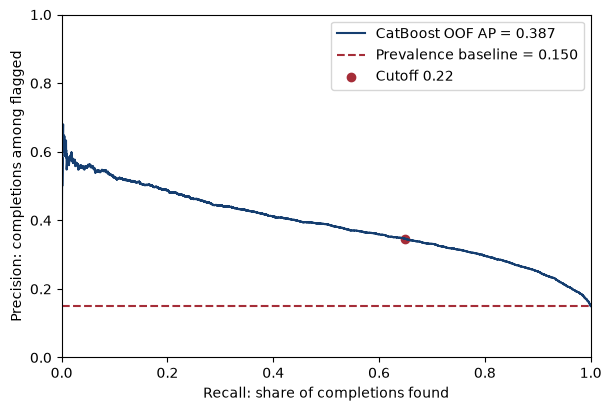

In [7]:
def metrics(target, probability, cutoff):
    predicted = probability >= cutoff
    return {'Average precision':average_precision_score(target,probability),
        'ROC-AUC':roc_auc_score(target,probability),
        'Precision':precision_score(target,predicted,zero_division=0),
        'Recall':recall_score(target,predicted,zero_division=0),
        'F1':f1_score(target,predicted,zero_division=0),
        'Accuracy':accuracy_score(target,predicted)}
cutoff_table = pd.DataFrame([{'Cutoff':float(c),'F1':f1_score(y_dev,selected_oof>=c,zero_division=0)}
    for c in np.round(np.arange(1,100)/100,2)])
# Stable tie-break: choose the lower cutoff among exact F1 ties.
cutoff_table = cutoff_table.sort_values(['F1','Cutoff'],ascending=[False,True])
selected_cutoff=float(cutoff_table.iloc[0].Cutoff)
dev_metrics=metrics(y_dev,selected_oof,selected_cutoff)
display(cutoff_table.head().round(4))
display(pd.DataFrame({f'Cutoff {c:.2f}':metrics(y_dev,selected_oof,c)
    for c in sorted(set([0.1,selected_cutoff,0.3,0.5]))}).round(4))
selection_record['threshold']=selected_cutoff
precision,recall,_=precision_recall_curve(y_dev,selected_oof)
fig,ax=plt.subplots(figsize=(6,4),layout='constrained')
ax.plot(recall,precision,color='#153E70',label=f'CatBoost OOF AP = {dev_metrics["Average precision"]:.3f}')
ax.axhline(y_dev.mean(),color='#A52D38',linestyle='--',label=f'Prevalence baseline = {y_dev.mean():.3f}')
ax.scatter(dev_metrics['Recall'],dev_metrics['Precision'],color='#A52D38',label=f'Cutoff {selected_cutoff:.2f}')
ax.set(xlabel='Recall: share of completions found',ylabel='Precision: completions among flagged',xlim=(0,1),ylim=(0,1))
ax.legend(); plt.show(); plt.close(fig)

## 5. Interpret reliance on inputs

For each fitted development-fold model, shuffle one **original** input in that fold's validation rows and measure the decrease in AP. Average three shuffles, then average across the five folds. Route is shuffled before endpoints are derived, so its score includes the endpoint features.

These are non-additive AP decreases, not percentages of total predictive power and not causal effects. Correlated inputs may share information, and shuffling a route while retaining flight duration can create implausible combinations. Fold variability and only three shuffles limit precision. The chart describes this model's reliance, not which customer behaviours should be changed.

,Mean AP drop,Fold SD
route,0.1095,0.0151
booking_origin,0.1090,0.0136
length_of_stay,0.0296,0.0089
wants_extra_baggage,0.0169,0.0061
sales_channel,0.0117,0.0030
purchase_lead,0.0087,0.0012
wants_preferred_seat,0.0078,0.0024
wants_in_flight_meals,0.0051,0.0024
flight_duration,0.0047,0.0057
flight_hour,0.0021,0.0010


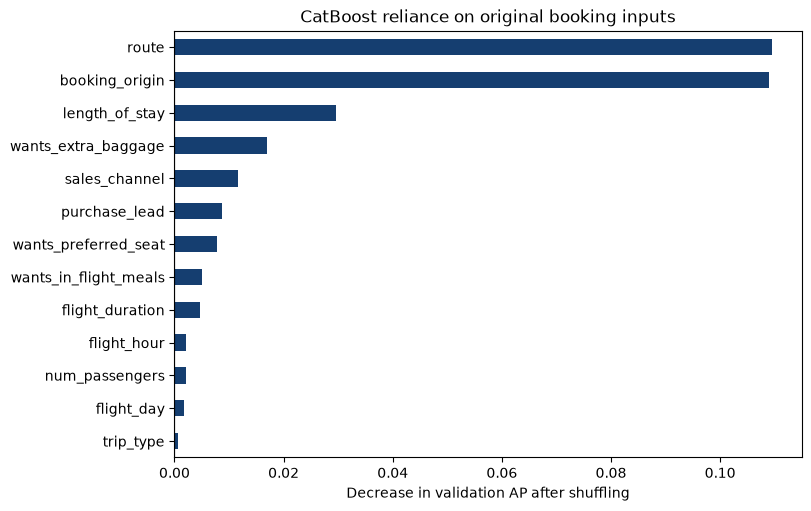

In [8]:
importance_runs=[]
for number, ((_,validation),fitted) in enumerate(zip(folds,selected_results['estimator']),1):
    importance=permutation_importance(fitted,X_dev.iloc[validation],y_dev.iloc[validation],
        scoring='average_precision',n_repeats=3,random_state=42,n_jobs=1)
    importance_runs.append(pd.Series(importance.importances_mean,index=X_dev.columns))
importance_by_fold=pd.DataFrame(importance_runs)
importance_table=pd.DataFrame({'Mean AP drop':importance_by_fold.mean(),
    'Fold SD':importance_by_fold.std()}).sort_values('Mean AP drop',ascending=False)
display(importance_table.round(4))
fig,ax=plt.subplots(figsize=(8,5),layout='constrained')
importance_table['Mean AP drop'].sort_values().plot.barh(ax=ax,color='#153E70')
ax.set(xlabel='Decrease in validation AP after shuffling',title='CatBoost reliance on original booking inputs')
ax.axvline(0,color='black',linewidth=.8)
plt.show(); plt.close(fig)

## 6. Evaluate on the holdout

Refit the chosen settings on all development rows, then apply the development-selected cutoff. The holdout was previously evaluated for the forest, so these results are a secondary check rather than an untouched final test.

The forest's saved intervals belong to the forest. We calculate separate CatBoost intervals by resampling identical-input groups from fixed holdout predictions. These intervals describe sampling variability conditional on the fitted model; they do not include model-selection uncertainty, training variation, unknown customer dependence, or distribution shift.

In [9]:
final_catboost=build_catboost(selected_settings).fit(X_dev,y_dev,classifier__cat_features=CATEGORICAL)
assert final_catboost.named_steps['classifier'].get_params()['iterations']==selected_settings['iterations']
X_holdout,y_holdout=X.iloc[reserved_rows].copy(),y.iloc[reserved_rows].copy()
holdout_probability=final_catboost.predict_proba(X_holdout)[:,1]
holdout_metrics=metrics(y_holdout,holdout_probability,selected_cutoff)
holdout_matrix=confusion_matrix(y_holdout,holdout_probability>=selected_cutoff,labels=[0,1])
historical_cache=np.load(FOREST_DIR / 'test_predictions.npz')
for key,expected in [('original_row',X_holdout.index),('target',y_holdout),('group',groups.iloc[reserved_rows])]:
    np.testing.assert_array_equal(historical_cache[key],expected)
forest_holdout_metrics=metrics(y_holdout,historical_cache['probability'],forest_manifest['threshold'])
for name,value in forest_holdout_metrics.items():
    np.testing.assert_allclose(value,forest_manifest['benchmark']['test_metrics'][name],atol=1e-12)
with (FOREST_DIR / 'random_forest_model.pkl').open('rb') as stream:
    forest_bundle=cloudpickle.load(stream)
np.testing.assert_allclose(forest_bundle['pipeline'].predict_proba(X_holdout)[:,1],historical_cache['probability'],rtol=0,atol=1e-12)
display(pd.DataFrame({'CatBoost development OOF':dev_metrics,
    'CatBoost holdout':holdout_metrics,'Forest holdout':forest_holdout_metrics}).round(4))
display(pd.DataFrame(holdout_matrix,index=['Actual no','Actual yes'],columns=['Predicted no','Predicted yes']))
print(f'Holdout prevalence {y_holdout.mean():.2%}; majority accuracy {1-y_holdout.mean():.2%}')
print('Brier score (lower is better):',round(brier_score_loss(y_holdout,holdout_probability),4),
      'constant development-prevalence baseline:',round(brier_score_loss(y_holdout,np.full(len(y_holdout),y_dev.mean())),4))

,CatBoost development OOF,CatBoost holdout,Forest holdout
Average precision,0.3874,0.3735,0.3700
ROC-AUC,0.7997,0.7882,0.7859
Precision,0.3465,0.3289,0.3444
Recall,0.6490,0.6409,0.6192
F1,0.4518,0.4347,0.4426
Accuracy,0.7635,0.7546,0.7704


,Predicted no,Predicted yes
Actual no,6620,1930
Actual yes,530,946


Holdout prevalence 14.72%; majority accuracy 85.28%
Brier score (lower is better): 0.1075 constant development-prevalence baseline: 0.1256


In [10]:
rng=np.random.default_rng(20261102)
unique_groups,inverse=np.unique(groups.iloc[reserved_rows].to_numpy(),return_inverse=True)
bootstrap=[]
for _ in range(1000):
    # Sampling each group once per draw preserves repeated-detail records together.
    counts=np.bincount(rng.integers(0,len(unique_groups),len(unique_groups)),minlength=len(unique_groups))
    weight=counts[inverse]
    target=y_holdout.to_numpy(); predicted=holdout_probability>=selected_cutoff
    bootstrap.append({'Average precision':average_precision_score(target,holdout_probability,sample_weight=weight),
        'ROC-AUC':roc_auc_score(target,holdout_probability,sample_weight=weight),
        'Precision':precision_score(target,predicted,sample_weight=weight,zero_division=0),
        'Recall':recall_score(target,predicted,sample_weight=weight,zero_division=0),
        'F1':f1_score(target,predicted,sample_weight=weight,zero_division=0)})
boot=pd.DataFrame(bootstrap)
intervals=pd.DataFrame({'Estimate':pd.Series(holdout_metrics),
    '95% lower':boot.quantile(.025),'95% upper':boot.quantile(.975)}).dropna()
display(intervals.round(4))

,Estimate,95% lower,95% upper
Average precision,0.3735,0.3507,0.3994
F1,0.4347,0.4149,0.4535
Precision,0.3289,0.3111,0.3466
ROC-AUC,0.7882,0.7761,0.7993
Recall,0.6409,0.6167,0.6662


## 7. Export one selected model and verify raw-input inference

The deployment bundle contains the development-fitted CatBoost, its cutoff and raw input schema. `predict_completed()` uses that bundle by default. The forest manifest and files remain unchanged historical evidence in `model/forest_benchmark/`. No ambiguous variable named `model` selects between them.

The helper checks required columns, missing values and basic domains, copies the data, orders columns consistently and derives the endpoints. It accepts extra columns but selects only the original 13 predictors, preventing accidental use of a supplied target. Unseen valid categories are supported by CatBoost. This is a local analysis artifact, not a production service. Pickle files should only be loaded from trusted sources.

In [11]:
bundle={'pipeline':final_catboost,'threshold':selected_cutoff,'required_raw_columns':RAW_COLUMNS,
        'selected_name':selected_name,'training_partition':'development only'}
with (SELECTED_DIR / 'catboost_bundle.pkl').open('wb') as stream:
    cloudpickle.dump(bundle,stream)
final_catboost.named_steps['classifier'].save_model(str(SELECTED_DIR / 'catboost_model.cbm'))
np.savez_compressed(SELECTED_DIR / 'development_predictions.npz',original_row=X_dev.index,
    target=y_dev,group=development_groups,fold=fold_id,probability=selected_oof)
np.savez_compressed(SELECTED_DIR / 'holdout_predictions.npz',original_row=X_holdout.index,
    target=y_holdout,group=groups.iloc[reserved_rows],probability=holdout_probability)
selected_manifest={**selection_record,'model':'CatBoost with route endpoints','versions':versions,
    'required_raw_columns':RAW_COLUMNS,'categorical_inputs':CATEGORICAL,
    'data_sha256':sha256(BASE / 'data/customer_booking.csv'),
    'inference_code_sha256':sha256(BASE / 'booking_model.py'),
    'evaluation_status':'Holdout evaluation; see notebook Section 6 for evaluation history',
    'mean_development_fold_AP':float(selected_results['test_AP'].mean()),
    'development_OOF_metrics':dev_metrics,'previously_used_holdout_metrics':holdout_metrics,
    'holdout_confusion_matrix':holdout_matrix.tolist(),
    'conditional_group_bootstrap_intervals':intervals.to_dict(orient='index'),
    'bootstrap':{'replicates':1000,'seed':20261102,'method':'group percentile bootstrap of fixed predictions'},
    'assets_sha256':{p.name:sha256(p) for p in SELECTED_DIR.iterdir() if p.name != 'manifest.json'}}
(SELECTED_DIR / 'manifest.json').write_text(json.dumps(selected_manifest,indent=2))
reloaded=load_selected(SELECTED_DIR)
sample=X_holdout.head(20).copy(); before=sample.copy(deep=True)
prediction=predict_completed(sample,reloaded)
pd.testing.assert_frame_equal(sample,before)
np.testing.assert_allclose(prediction.completion_probability,holdout_probability[:20],rtol=0,atol=1e-12)
pd.testing.assert_frame_equal(prediction,predict_completed(sample[list(reversed(sample.columns))],reloaded))
pd.testing.assert_frame_equal(prediction,predict_completed(sample.assign(booking_complete=1),reloaded))
np.testing.assert_array_equal(prediction.predicted_complete,(prediction.completion_probability>=selected_cutoff).astype(int))
unseen=sample.iloc[:1].copy(); unseen['booking_origin']='Unseen country'; unseen['route']='ZZZYYY'
assert np.isfinite(predict_completed(unseen,reloaded).completion_probability).all()
for invalid in [sample.drop(columns='route'),sample.assign(route='bad'),sample.assign(purchase_lead=np.nan)]:
    try:
        predict_completed(invalid,reloaded)
    except ValueError:
        pass
    else:
        raise AssertionError('Invalid raw input was accepted')
# Native CatBoost export must agree as well; the pipeline still supplies preprocessing.
native=CatBoostClassifier(); native.load_model(str(SELECTED_DIR / 'catboost_model.cbm'))
np.testing.assert_allclose(native.predict_proba(add_airport_endpoints(sample))[:,1],prediction.completion_probability,atol=1e-12)
for filename,expected in forest_manifest['assets_sha256'].items():
    assert sha256(FOREST_DIR / filename)==expected
print('Verified round-trip serialization, raw/reordered/extra columns, unseen categories, input validation and unchanged forest assets.')
display(prediction.head())

Verified round-trip serialization, raw/reordered/extra columns, unseen categories, input validation and unchanged forest assets.


,completion_probability,predicted_complete
1,0.025361,0
5,0.058486,0
7,0.058432,0
11,0.064837,0
12,0.026907,0


## 8. Conclusions and next steps

The cells below generate the reported numbers from this execution. Interpret small model differences cautiously, given the repeated development comparisons. A larger training score does not imply a better model. Training AP is especially optimistic for flexible models and is only an overfitting diagnostic.

These results apply to the supplied simulation records; their representativeness of British Airways customers is not established. The sensible next step is to confirm input availability and a business use case, then evaluate on a genuinely fresh dated sample. Any marketing trial would need to measure incremental bookings and contact cost: a model that predicts existing purchase propensity does not show whom marketing will persuade. Additional parameter search is not a substitute for that evidence.

In [12]:
summary = f"""**Selected model:** CatBoost (`{selected_name}`), cutoff **{selected_cutoff:.2f}** chosen on development OOF F1.

- Mean development-fold AP **{selected_results['test_AP'].mean():.4f}**; pooled OOF AP **{dev_metrics['Average precision']:.4f}**. Constant-score baseline AP is **{y_dev.mean():.4f}**.
- Holdout: AP **{holdout_metrics['Average precision']:.4f}**, ROC-AUC **{holdout_metrics['ROC-AUC']:.4f}**, precision **{holdout_metrics['Precision']:.1%}**, recall **{holdout_metrics['Recall']:.1%}**, F1 **{holdout_metrics['F1']:.4f}**.
- This flags **{int((holdout_probability>=selected_cutoff).sum()):,}** records and finds **{holdout_matrix[1,1]:,}** of **{int(y_holdout.sum()):,}** completions, with **{holdout_matrix[0,1]:,}** false positives and **{holdout_matrix[1,0]:,}** missed completions.
- CatBoost's holdout AP difference from the forest is **{holdout_metrics['Average precision']-forest_holdout_metrics['Average precision']:+.4f}**. Forest F1 is **{forest_holdout_metrics['F1']:.4f}** at its recorded cutoff. CatBoost does not necessarily win on every metric.
- Route (including endpoints) and booking origin dominate permutation importance. These are predictive associations, not causal marketing effects.
- The always-negative baseline achieves **{1-y_holdout.mean():.1%}** holdout accuracy with **zero recall**. Our model's **{holdout_metrics['Accuracy']:.1%}** accuracy should be considered alongside the completions it finds.

**Recommendation:** treat this as a promising booking-stage prioritisation prototype. Confirm when inputs become available, set a cutoff using business costs/capacity, and validate on fresh dated data before a controlled pilot. The current evidence does not establish new-customer generalisation or incremental revenue.
"""
display(Markdown(summary))
report={'audit_counts':audit_counts,'selected_model':selected_manifest,
    'comparison':comparison.to_dict(orient='index'),'experiments':search_summary.to_dict(orient='index'),
    'importance':importance_table.to_dict(orient='index'),'holdout_prevalence':float(y_holdout.mean()),
    'development_prevalence':float(y_dev.mean())}
(RESULTS_DIR / 'verified_results.json').write_text(json.dumps(report,indent=2))

**Selected model:** CatBoost (`original_d6_i500`), cutoff **0.22** chosen on development OOF F1.

- Mean development-fold AP **0.3905**; pooled OOF AP **0.3874**. Constant-score baseline AP is **0.1501**.
- Holdout: AP **0.3735**, ROC-AUC **0.7882**, precision **32.9%**, recall **64.1%**, F1 **0.4347**.
- This flags **2,876** records and finds **946** of **1,476** completions, with **1,930** false positives and **530** missed completions.
- CatBoost's holdout AP difference from the forest is **+0.0035**. Forest F1 is **0.4426** at its recorded cutoff. CatBoost does not necessarily win on every metric.
- Route (including endpoints) and booking origin dominate permutation importance. These are predictive associations, not causal marketing effects.
- The always-negative baseline achieves **85.3%** holdout accuracy with **zero recall**. Our model's **75.5%** accuracy should be considered alongside the completions it finds.

**Recommendation:** treat this as a promising booking-stage prioritisation prototype. Confirm when inputs become available, set a cutoff using business costs/capacity, and validate on fresh dated data before a controlled pilot. The current evidence does not establish new-customer generalisation or incremental revenue.


7714

## Sources and reproducibility notes

- [Forage Task 2, steps 1–3](https://www.theforage.com/virtual-experience/NjynCWzGSaWXQCxSX/british-airways/data-science-yqoz/predicting-customer-buying-behaviour?step=3), reviewed 2 November 2026 (America/New_York). One slide required, upload not performed. Steps 4–5 remain locked before submission.
- [Starter notebook](https://cdn.theforage.com/vinternships/companyassets/tMjbs76F526fF5v3G/L3MQ8f6cYSkfoukmz/1666877712550/Getting%20Started.ipynb), saved in `resources/`, provides the field definitions.
- [Original CSV](https://cdn.theforage.com/vinternships/companyassets/tMjbs76F526fF5v3G/L3MQ8f6cYSkfoukmz/1667814300249/customer_booking.csv), independently downloaded and byte-compared with the working CSV. Forage labels it for simulation use only.
- [scikit-learn supervised learning](https://scikit-learn.org/stable/supervised_learning.html), [evaluation metrics](https://scikit-learn.org/stable/modules/model_evaluation.html), and [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
- [CatBoost parameter tuning](https://catboost.ai/docs/en/concepts/parameter-tuning), for the bounded regularization and learning-rate checks.

The audit refits models in a fresh kernel and checks saved forest predictions against fresh fold fits. Hashes verify file integrity, not the history of evaluation decisions. `model/forest_benchmark/manifest.json` is the unchanged historical forest record, including statements written before CatBoost development; `model/selected/manifest.json` is the current selected-model record. Empty and superseded notebooks were removed during folder cleanup.

This notebook recomputes experiments on Run All. Saved selected predictions are exported evidence, not a hidden shortcut for later experiments. The full environment lock accompanies the core requirements. No package upgrades or Task 1 edits were made.